# Hyperparameter Tuning and Model Comparison: Setting 2 (Task 2)
**CM2604 Machine Learning, Part 01**

Run `models_baseline.ipynb` first (it saves the default-setting results).

**Experimental settings compared**
1. **Setting 1:** default hyperparameters (previous notebook).
2. **Setting 2:** tuned hyperparameters, found with cross-validation on the training set only.

**Tuning metric: F1 score** of the churn class. With imbalanced data, accuracy rewards always predicting "stay", while F1 balances precision and recall for the class we care about.

In [13]:
import sys
sys.path.append("../src")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay,
                             classification_report)

from preprocessing import load_and_clean, split_data, build_preprocessor, RANDOM_STATE
from evaluation import evaluate, results_table

sns.set_theme(style="whitegrid")
os.makedirs("../figures", exist_ok=True)

df = load_and_clean()
X_train, X_test, y_train, y_test = split_data(df)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_pipeline(model):
    return Pipeline([("prep", build_preprocessor(X_train)), ("model", model)])

## 1. Search spaces
Parameter names use the `model__` prefix because the model sits inside a pipeline.

| Model | Tuned parameters | Search |
|---|---|---|
| KNN | `n_neighbors`, `weights`, distance `metric` | Grid (small space) |
| Logistic Regression | `C` (regularisation strength), `l1_ratio` (0 = L2, 1 = L1 penalty), `class_weight` | Grid |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf`, `class_weight` | Randomised, 30 samples (large space) |

`class_weight="balanced"` is included as a search option for Logistic Regression and Random Forest so that imbalance handling is tested, not assumed.

In [14]:
searches = {
    "KNN": GridSearchCV(
        make_pipeline(KNeighborsClassifier()),
        {"model__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31],
         "model__weights": ["uniform", "distance"],
         "model__metric": ["euclidean", "manhattan"]},
        scoring="f1", cv=cv, n_jobs=-1),

    "Logistic Regression": GridSearchCV(
        make_pipeline(LogisticRegression(solver="liblinear", max_iter=1000, random_state=RANDOM_STATE)),
        {"model__C": [0.01, 0.1, 1, 10, 100],
         "model__l1_ratio": [0, 1],            # 0 = L2 penalty, 1 = L1 penalty
         "model__class_weight": [None, "balanced"]},
        scoring="f1", cv=cv, n_jobs=-1),

    "Random Forest": RandomizedSearchCV(
        make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE)),
        {"model__n_estimators": [100, 200, 300],
         "model__max_depth": [None, 6, 8, 12, 20],
         "model__min_samples_split": [2, 5, 10],
         "model__min_samples_leaf": [1, 2, 4],
         "model__class_weight": [None, "balanced"]},
        n_iter=30, scoring="f1", cv=cv, n_jobs=-1, random_state=RANDOM_STATE),
}

## 2. Run the searches (training data only)

In [15]:
for name, search in searches.items():
    search.fit(X_train, y_train)
    print(f"{name}: best CV F1 = {search.best_score_:.4f}")
    print("   best params:", {k.replace("model__", ""): v for k, v in search.best_params_.items()})

KNN: best CV F1 = 0.6001
   best params: {'metric': 'euclidean', 'n_neighbors': 31, 'weights': 'uniform'}
Logistic Regression: best CV F1 = 0.6320
   best params: {'C': 0.1, 'class_weight': 'balanced', 'l1_ratio': 0}
Random Forest: best CV F1 = 0.6382
   best params: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_depth': 20, 'class_weight': 'balanced'}


## 3. Evaluate the tuned models on the unseen test set

In [16]:
tuned_rows = [evaluate(s.best_estimator_, X_test, y_test, name, "Tuned")
              for name, s in searches.items()]
tuned = results_table(tuned_rows)
baseline = pd.read_csv("../results/baseline_results.csv")

comparison = pd.concat([baseline, tuned]).sort_values(["Model", "Setting"]).reset_index(drop=True)
comparison.to_csv("../results/model_comparison.csv", index=False)
comparison

,Model,Setting,Accuracy,Precision,Recall,F1,ROC-AUC
0,KNN,Default,0.7630,0.5538,0.5508,0.5523,0.7919
1,KNN,Tuned,0.7956,0.6236,0.5802,0.6011,0.8327
2,Logistic Regression,Default,0.8055,0.6582,0.5561,0.6029,0.8422
3,Logistic Regression,Tuned,0.7438,0.5113,0.7834,0.6188,0.8412
4,Random Forest,Default,0.7956,0.6473,0.5053,0.5676,0.8258
5,Random Forest,Tuned,0.7601,0.5335,0.7674,0.6294,0.8429


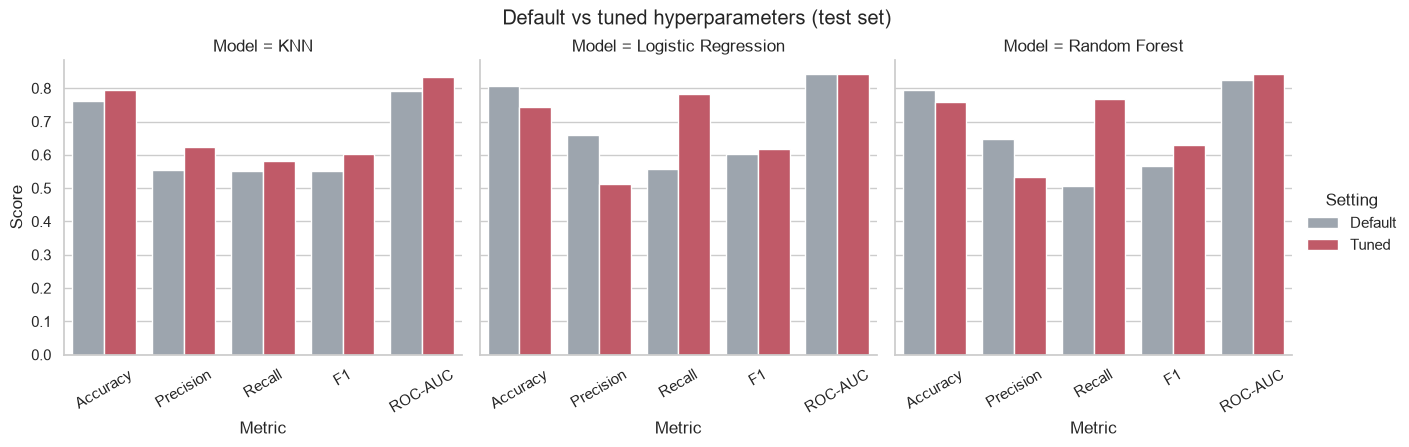

In [17]:
# Default vs tuned, per metric
metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
long = comparison.melt(id_vars=["Model", "Setting"], value_vars=metrics, var_name="Metric", value_name="Score")

g = sns.catplot(data=long, x="Metric", y="Score", hue="Setting", col="Model", kind="bar",
                palette=["#9AA5B1", "#D1495B"], height=4, aspect=1.1)
g.set_xticklabels(rotation=30)
g.fig.suptitle("Default vs tuned hyperparameters (test set)", y=1.03)
plt.savefig("../figures/08_default_vs_tuned.png", bbox_inches="tight"); plt.show()

## 4. Confusion matrices and ROC curves (tuned models, test set)

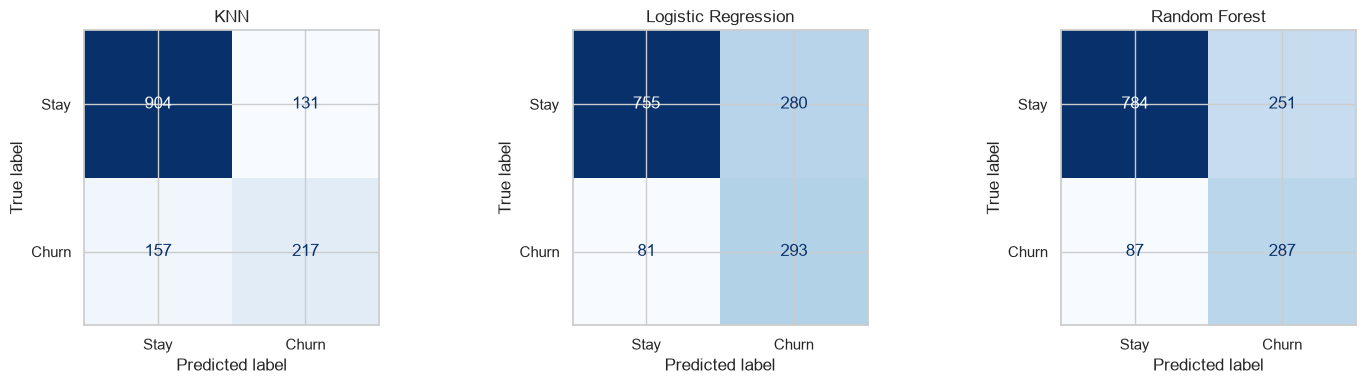

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, s) in zip(axes, searches.items()):
    ConfusionMatrixDisplay.from_estimator(s.best_estimator_, X_test, y_test,
        display_labels=["Stay", "Churn"], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout(); plt.savefig("../figures/09_confusion_matrices.png"); plt.show()

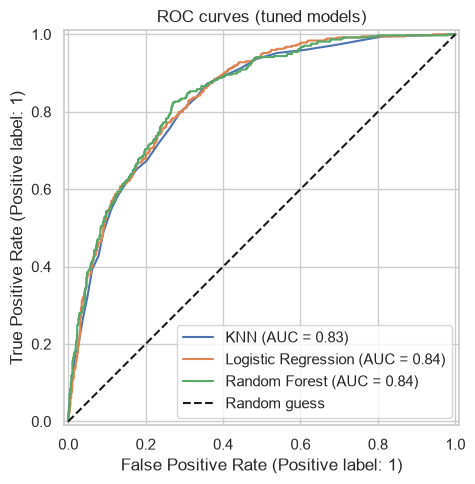

In [19]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, s in searches.items():
    RocCurveDisplay.from_estimator(s.best_estimator_, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("ROC curves (tuned models)"); ax.legend()
plt.tight_layout(); plt.savefig("../figures/10_roc_curves.png"); plt.show()

In [20]:
for name, s in searches.items():
    print("=" * 55, "\n", name, "(tuned)")
    print(classification_report(y_test, s.best_estimator_.predict(X_test),
                                target_names=["Stay", "Churn"], digits=3))

 KNN (tuned)
              precision    recall  f1-score   support

        Stay      0.852     0.873     0.863      1035
       Churn      0.624     0.580     0.601       374

    accuracy                          0.796      1409
   macro avg      0.738     0.727     0.732      1409
weighted avg      0.791     0.796     0.793      1409

 Logistic Regression (tuned)
              precision    recall  f1-score   support

        Stay      0.903     0.729     0.807      1035
       Churn      0.511     0.783     0.619       374

    accuracy                          0.744      1409
   macro avg      0.707     0.756     0.713      1409
weighted avg      0.799     0.744     0.757      1409

 Random Forest (tuned)
              precision    recall  f1-score   support

        Stay      0.900     0.757     0.823      1035
       Churn      0.533     0.767     0.629       374

    accuracy                          0.760      1409
   macro avg      0.717     0.762     0.726      1409
weighted 

## 5. What drives the predictions?

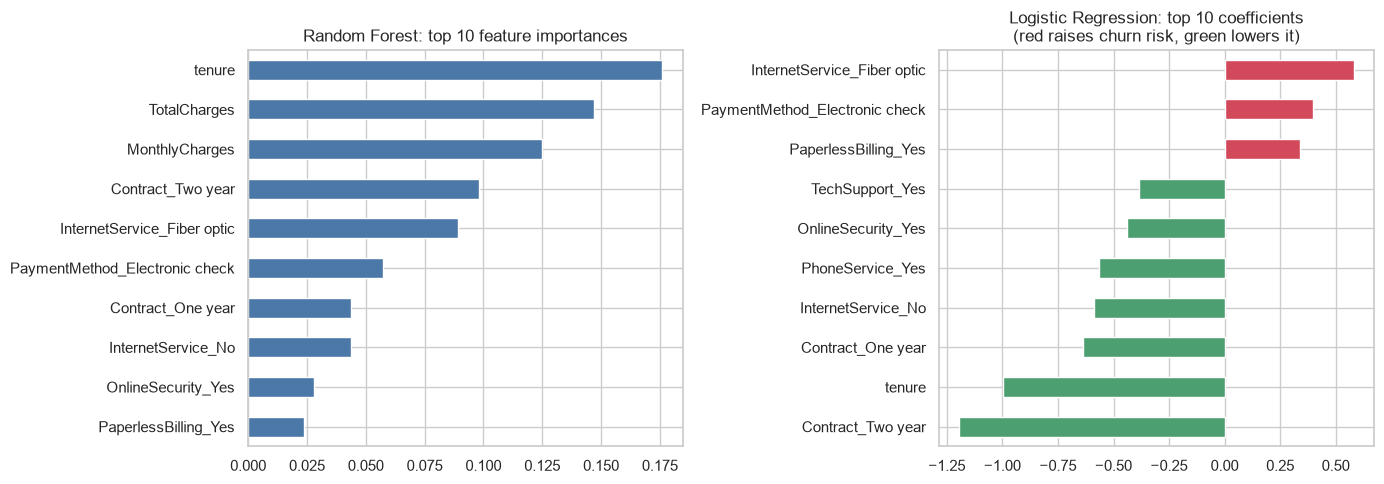

In [21]:
feature_names = searches["Random Forest"].best_estimator_["prep"].get_feature_names_out()
feature_names = [n.split("__", 1)[1] for n in feature_names]

rf = searches["Random Forest"].best_estimator_["model"]
lr = searches["Logistic Regression"].best_estimator_["model"]

imp = pd.Series(rf.feature_importances_, index=feature_names).sort_values().tail(10)
coef = pd.Series(lr.coef_[0], index=feature_names)
coef = coef.reindex(coef.abs().sort_values().tail(10).index).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
imp.plot(kind="barh", color="#4C78A8", ax=axes[0]); axes[0].set_title("Random Forest: top 10 feature importances")
coef.plot(kind="barh", color=["#D1495B" if v > 0 else "#4C9F70" for v in coef], ax=axes[1])
axes[1].set_title("Logistic Regression: top 10 coefficients\n(red raises churn risk, green lowers it)")
plt.tight_layout(); plt.savefig("../figures/11_feature_drivers.png"); plt.show()

## 6. Discussion (complete after running; compare with your own numbers)
- Compare **Default vs Tuned** in the table and bar chart. Look especially at **recall and F1**, which are the metrics that matter for churn.
- Check whether tuning picked `class_weight="balanced"`. If so, recall rises at the cost of some precision and accuracy, which is usually a worthwhile trade for retention campaigns.
- Compare the **cross-validation F1** printed in section 2 with the **test F1** in section 3. A small gap means the model generalises and the tuning did not overfit the training data.
- Use the confusion matrices to explain the cost of errors: a false negative is a churner we miss, a false positive is a retention offer sent to someone who would have stayed.
- The feature-driver plots should match the EDA: tenure, contract type, internet service and monthly charges.